# 03 · Análisis espacial: tasas anuales y hotspots Getis-Ord Gi*

1. **Tasa anual** por 100 mil habitantes por área comunitaria (población del censo 2020, CMAP), promediada en 2019–2025.
2. **Getis-Ord Gi\*** sobre una grilla de 1 km para cada año, con corrección FDR.
3. **Estabilidad** de los hotspots entre años con el índice de Jaccard.

In [1]:
import json
import warnings
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display
from delitos_chicago.config import FIGURAS, PROCESADOS, REPORTES
import delitos_chicago.pipeline  # los módulos fijan el backend Agg al importarse; después se activa el inline
%matplotlib inline
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

In [2]:
from delitos_chicago.pipeline import cargar_datos
from delitos_chicago.pronostico import ultimo_mes_completo
df, renombres, conteos = cargar_datos(PROCESADOS / "delitos_parquet")
mes_completo = ultimo_mes_completo(df["fecha"].max())
anio_completo = mes_completo.year if mes_completo.month == 12 else mes_completo.year - 1
completos = df[df["anio"] <= anio_completo]
print(f"{len(df):,} registros · último dato {df['fecha'].max():%Y-%m-%d} · último mes completo {mes_completo:%Y-%m} · años completos 2001–{anio_completo}")

8,665,676 registros · último dato 2026-10-16 · último mes completo 2026-09 · años completos 2001–2025


## 1. Tasas anuales por área comunitaria

In [3]:
from delitos_chicago import espacial
from delitos_chicago.config import ANIOS_ESPACIALES
poblacion = espacial.cargar_poblacion()
areas = espacial.cargar_geojson_areas()
tasas = espacial.tasas_anuales_area(completos, poblacion)
resumen = espacial.resumen_areas(tasas[tasas["anio"].isin(ANIOS_ESPACIALES)], areas.set_index("area_comunitaria")["nombre_area"])
resumen.head(10)

,area_comunitaria,nombre_area,poblacion_2020,delitos_promedio_anual,tasa_anual_100k,puesto_tasa,puesto_volumen,rank_tasa_promedio,rank_tasa_desv,rank_tasa_mejor,rank_tasa_peor,tasa_arresto_pct,anios
0,26,West Garfield Park,17433,4389,25176,1,18,1.3,0.8,1,3,32.6,7
1,68,Englewood,24369,5156,21157,2,14,2.4,1.0,1,4,18.2,7
2,29,North Lawndale,34794,7134,20505,3,6,4.0,2.0,2,7,27.0,7
3,27,East Garfield Park,19992,3982,19919,4,20,4.1,1.1,2,5,21.8,7
4,69,Greater Grand Crossing,32207,6255,19420,5,10,4.9,1.8,3,8,15.6,7
5,40,Washington Park,12707,2292,18036,6,37,6.9,2.6,2,10,13.2,7
6,37,Fuller Park,3893,702,18025,7,71,7.7,1.4,5,9,19.8,7
7,44,Chatham,32929,5914,17959,8,11,7.9,1.2,6,9,14.8,7
8,67,West Englewood,29647,5120,17270,9,15,9.3,3.9,4,14,18.8,7
9,32,Loop,47614,8020,16844,10,5,11.6,8.0,4,25,18.2,7


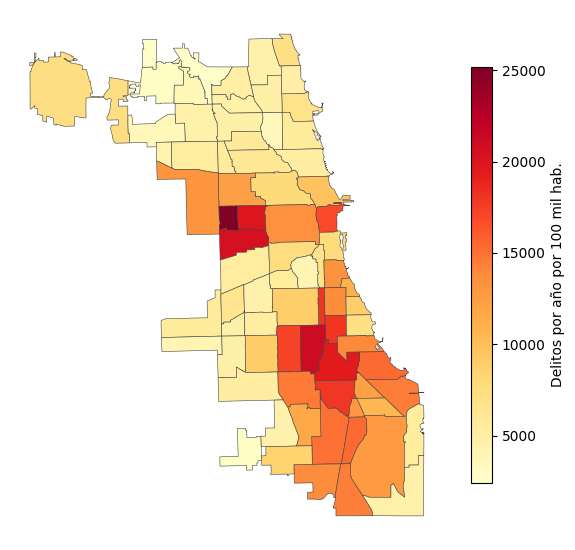

In [4]:
mapa = areas.merge(resumen[["area_comunitaria", "tasa_anual_100k"]], on="area_comunitaria")
fig, ax = plt.subplots(figsize=(7, 9))
mapa.plot(column="tasa_anual_100k", cmap="YlOrRd", edgecolor="#424242", linewidth=0.4, legend=True, ax=ax,
          legend_kwds={"label": "Delitos por año por 100 mil hab.", "shrink": 0.6})
ax.axis("off")
plt.show()

In [5]:
# Volumen frente a tasa: las áreas con más delitos no son las de más delitos por habitante
resumen.sort_values("puesto_volumen").head(5)[["nombre_area", "delitos_promedio_anual", "poblacion_2020", "tasa_anual_100k", "puesto_tasa"]]

,nombre_area,delitos_promedio_anual,poblacion_2020,tasa_anual_100k,puesto_tasa
21,Austin,12737,96557,13191,22
29,Near North Side,10401,106983,9722,30
19,Near West Side,9164,67881,13501,20
11,South Shore,8261,53971,15306,12
9,Loop,8020,47614,16844,10


## 2. Getis-Ord Gi* por año

In [6]:
grilla = espacial.conteos_grilla(completos, ANIOS_ESPACIALES, 1000)
gi = espacial.hotspots_gi(grilla)
estab, resumen_gi = espacial.estabilidad_hotspots(gi)
estab

,anio,celdas_hotspot,pct_celdas,pct_delitos_en_hotspots,celdas_coldspot,jaccard_vs_anio_anterior,jaccard_vs_2019
0,2019,57,8.5,27.2,0,NaN,1.000
1,2020,86,12.8,34.5,2,0.644,0.644
2,2021,83,12.4,33.1,2,0.878,0.687
3,2022,64,9.5,27.6,0,0.652,0.681
4,2023,57,8.5,24.1,0,0.833,0.676
5,2024,57,8.5,24.6,0,0.869,0.701
6,2025,59,8.8,25.6,0,0.871,0.611


In [7]:
resumen_gi

{'anios': [2019, 2020, 2021, 2022, 2023, 2024, 2025],
 'celdas_area_estudio': 672,
 'celdas_hotspot_todos_los_anios': 42,
 'celdas_hotspot_alguna_vez': 100,
 'pct_persistentes_sobre_alguna_vez': 42.0,
 'pct_hotspots_primer_anio_que_siguen_ultimo': 77.2,
 'jaccard_consecutivo_promedio': 0.791,
 'jaccard_primer_vs_ultimo': 0.611,
 'pct_delitos_ultimo_anio_en_persistentes': 18.7,
 'pct_celdas_persistentes': 6.2}

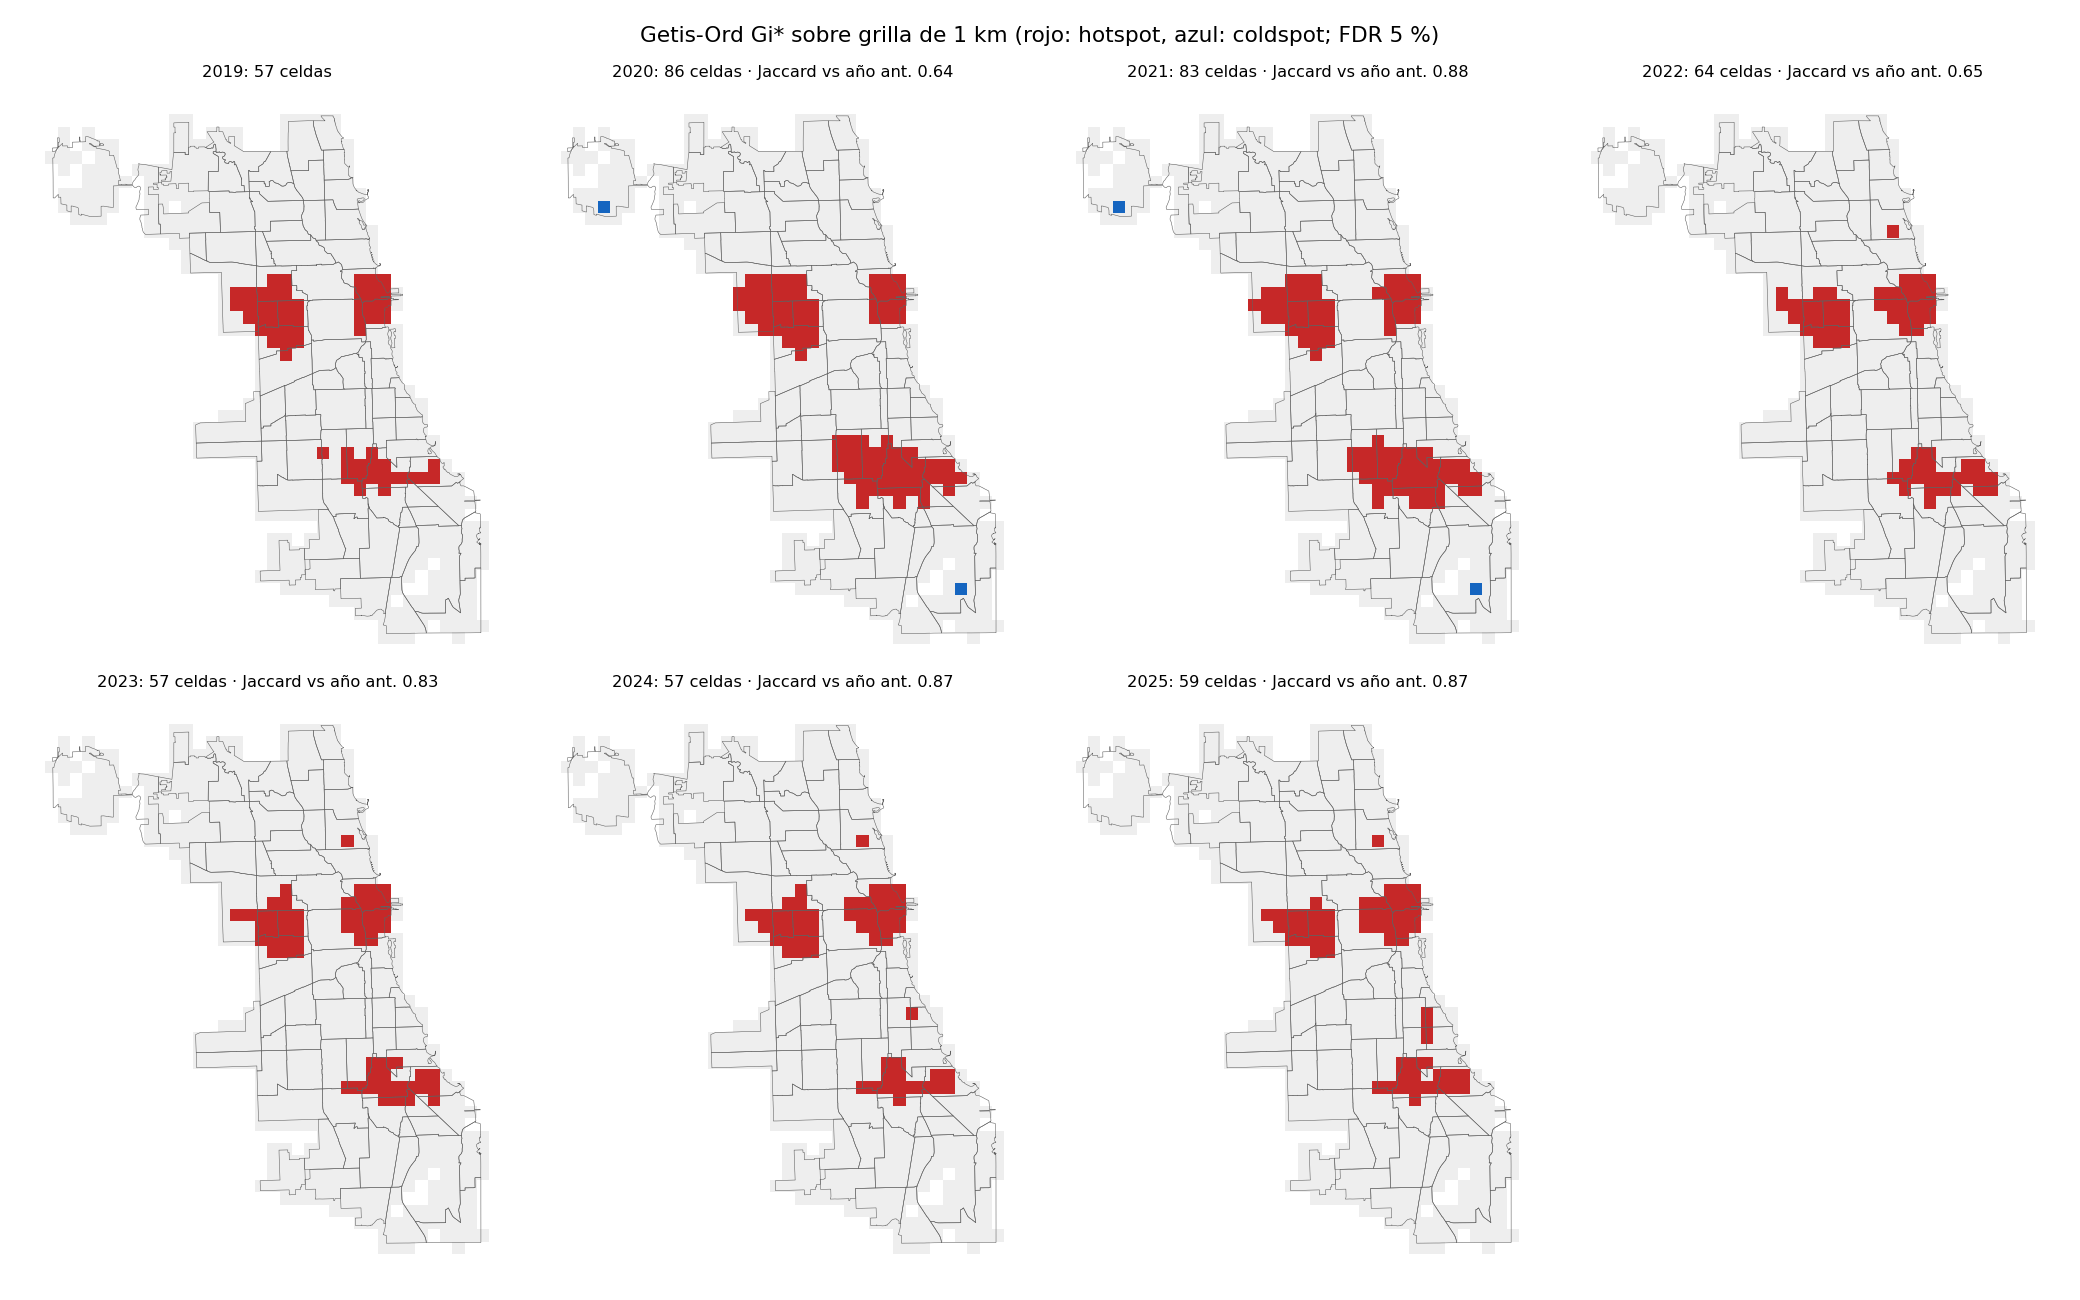

In [8]:
espacial.graficar_hotspots_por_anio(gi, areas, estab, 1000)
display(Image(filename=str(FIGURAS / "12_hotspots_gi_por_anio.png"), width=1000))

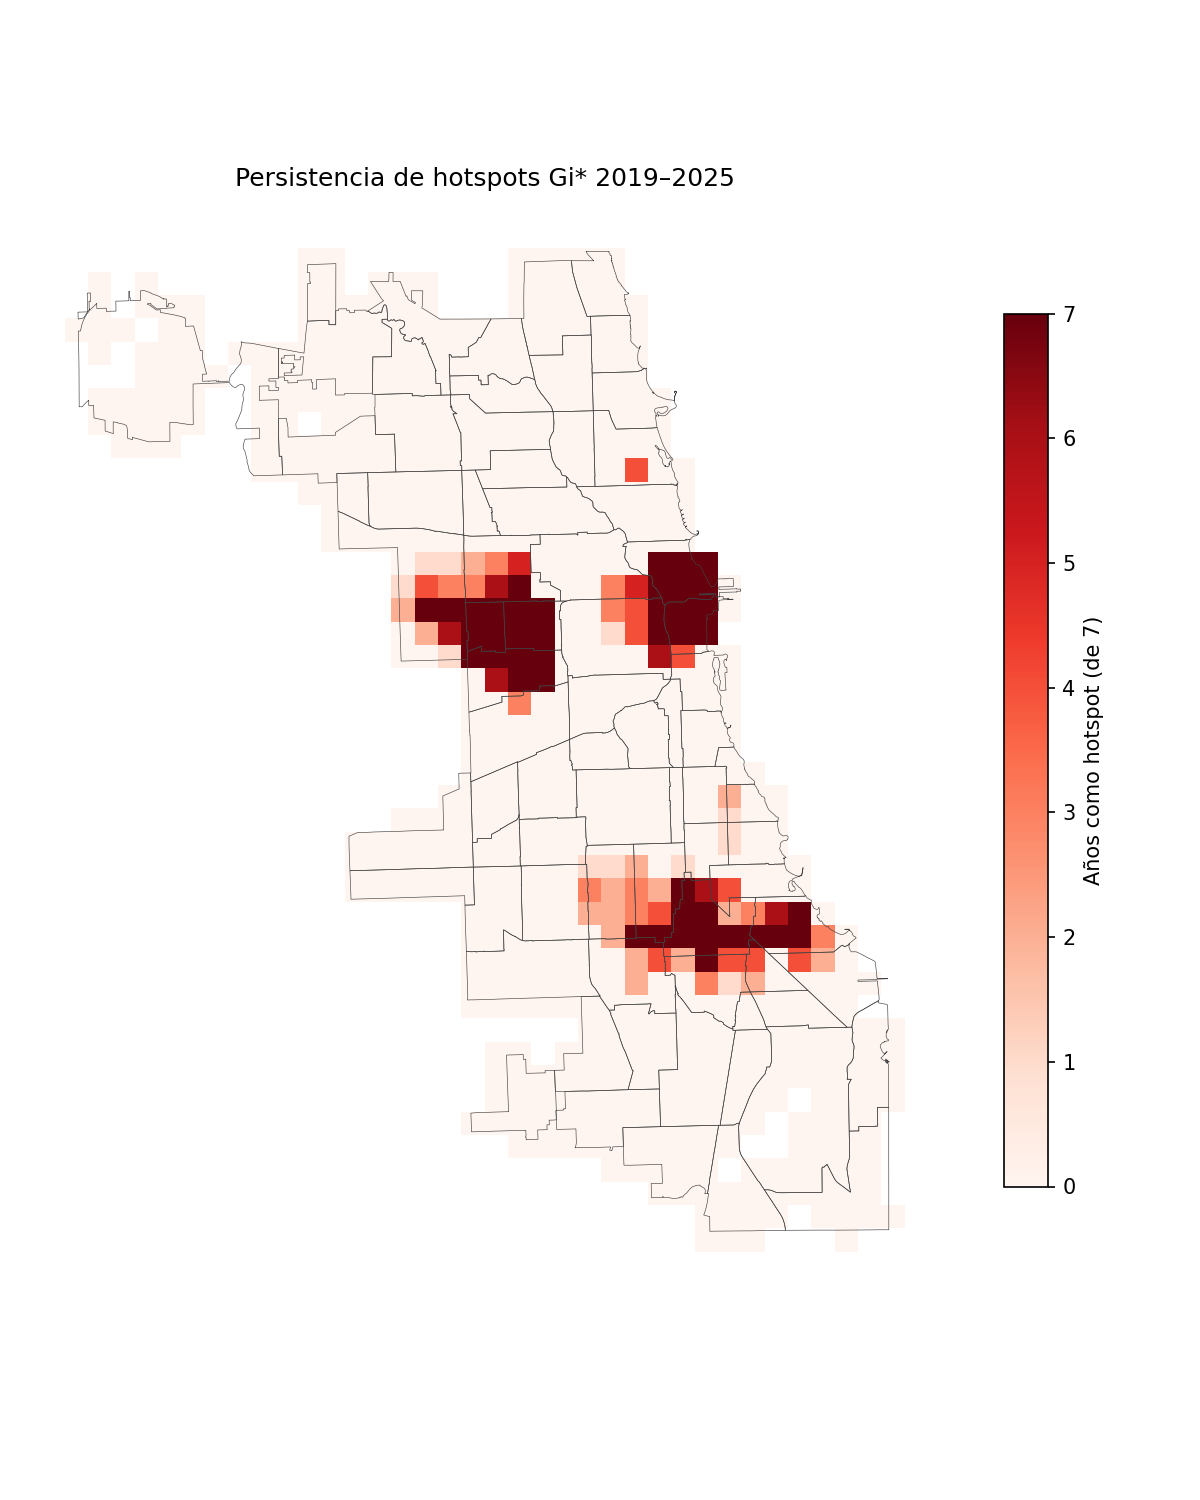

,area_comunitaria,nombre_area,celdas_persistentes
0,69,Greater Grand Crossing,6
1,29,North Lawndale,6
2,8,Near North Side,5
3,26,West Garfield Park,4
4,43,South Shore,4
5,27,East Garfield Park,4
6,32,Loop,4
7,25,Austin,2


In [9]:
espacial.graficar_persistencia(gi, areas, 1000)
display(Image(filename=str(FIGURAS / "13_persistencia_hotspots.png"), width=550))
espacial.areas_de_hotspots_persistentes(gi, areas, 1000).head(8)

Los hotspots son estables (Jaccard alto entre años consecutivos) y se concentran en el oeste, el centro y el sur. Gi\* usa conteos por celda: un hotspot en el Loop refleja mucha actividad y población flotante, no necesariamente más riesgo por residente.